In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [13]:
# Sentiment Analysis on Alexa Reviews Dataset

# Import Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Load Dataset
df = pd.read_csv("/kaggle/input/datasets/sid321axn/amazon-alexa-reviews/amazon_alexa.tsv", sep='\t')

# Display first few rows
print(df.head())

# Check dataset information
print(df.info())

# Check missing values
print(df.isnull().sum())
print(df.shape)

   rating       date         variation  \
0       5  31-Jul-18  Charcoal Fabric    
1       5  31-Jul-18  Charcoal Fabric    
2       4  31-Jul-18    Walnut Finish    
3       5  31-Jul-18  Charcoal Fabric    
4       5  31-Jul-18  Charcoal Fabric    

                                    verified_reviews  feedback  
0                                      Love my Echo!         1  
1                                          Loved it!         1  
2  Sometimes while playing a game, you can answer...         1  
3  I have had a lot of fun with this thing. My 4 ...         1  
4                                              Music         1  
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3150 entries, 0 to 3149
Data columns (total 5 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   rating            3150 non-null   int64 
 1   date              3150 non-null   object
 2   variation         3150 non-null   object
 3   verified_reviews

In [5]:
#getting the record where "verified revies " are null
df[df["verified_reviews"].isna()== True]

,rating,date,variation,verified_reviews,feedback
473,2,29-Jun-18,White,NaN,0


In [11]:
# we will drop the null record

df.dropna(inplace=True)

In [12]:
print(f"dataset shape after droping null values: {df.shape}")

dataset shape after droping null values: (3149, 5)


In [21]:
#creating a new coloumn 'length' that will contain the lenghgt of the string in 'verified_reviews' coloumns
df.dropna(subset=['verified_reviews'], inplace=True)
df['length'] =df['verified_reviews'].apply(len)

In [23]:
print(df.head())

   rating       date         variation  \
0       5  31-Jul-18  Charcoal Fabric    
1       5  31-Jul-18  Charcoal Fabric    
2       4  31-Jul-18    Walnut Finish    
3       5  31-Jul-18  Charcoal Fabric    
4       5  31-Jul-18  Charcoal Fabric    

                                    verified_reviews  feedback  length  
0                                      Love my Echo!         1      13  
1                                          Loved it!         1       9  
2  Sometimes while playing a game, you can answer...         1     195  
3  I have had a lot of fun with this thing. My 4 ...         1     172  
4                                              Music         1       5  


In [25]:
# Features and Target
X = df['verified_reviews']
y = df['feedback']    # 1 = Positive, 0 = Negative

In [26]:
# Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [27]:
# Convert text into numerical vectors
tfidf = TfidfVectorizer(
    stop_words='english',   #the , is , are
    max_features=5000
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

In [65]:
# Train Model
model = LogisticRegression(class_weight="balanced")
model.fit(X_train_tfidf, y_train)

# Predictions
y_pred = model.predict(X_test_tfidf)

# Accuracy
accuracy = accuracy_score(y_test, y_pred)
print("Accuracy:", accuracy)

# Classification Report
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Accuracy: 0.9063492063492063

Classification Report:
              precision    recall  f1-score   support

           0       0.45      0.76      0.57        51
           1       0.98      0.92      0.95       579

    accuracy                           0.91       630
   macro avg       0.72      0.84      0.76       630
weighted avg       0.94      0.91      0.92       630



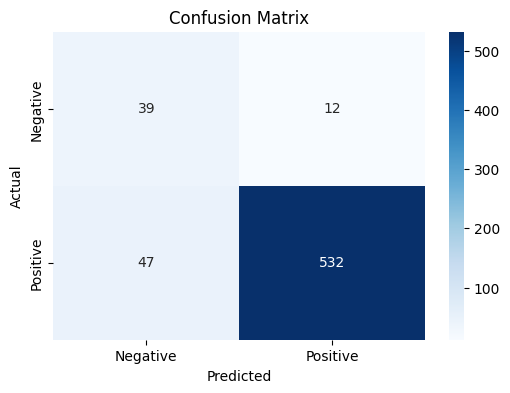

In [66]:
# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6,4))
sns.heatmap(cm,
            annot=True,
            fmt='d',
            cmap='Blues',
            xticklabels=['Negative','Positive'],
            yticklabels=['Negative','Positive'])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()


In [67]:
# Function for Custom Review Prediction
def predict_sentiment(review):
    review_vector = tfidf.transform([review])
    prediction = model.predict(review_vector)[0]

    if prediction == 1:
        return "Positive 😊"
    else:
        return "Negative 😞"
        

In [68]:
# Testing
print(predict_sentiment("This Alexa device is amazing and very useful"))
print(predict_sentiment("Worst product, useless money waste , time waste , power waste"))

Positive 😊
Negative 😞
